<a href="https://colab.research.google.com/github/Bishesh-P/Drowsiness-Detection-Using-YOLO/blob/main/Drowsiness_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch

In [ ]:
!git clone https://github.com/ultralytics/yolov5

Cloning into 'yolov5'...
remote: Enumerating objects: 18806, done.
remote: Counting objects: 100% (358/358), done.
remote: Compressing objects: 100% (215/215), done.
remote: Total 18806 (delta 298), reused 143 (delta 143), pack-reused 18448 (from 2)
Receiving objects: 100% (18806/18806), 17.75 MiB | 19.20 MiB/s, done.
Resolving deltas: 100% (12819/12819), done.


In [ ]:
!cd yolov5/
!pip install -r requirements.txt

/bin/bash: line 1: cd: yolov5/: No such file or directory
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 12.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [ ]:
model = torch.hub.load('ultralytics/yolov5', 'yolov5m')

YOLOv5 🚀 2026-10-29 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)



Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


100%|██████████| 40.8M/40.8M [00:00<00:00, 101MB/s] 

Fusing layers... 
YOLOv5m summary: 168 layers, 21,172,173 parameters, 0 gradients, 48.9 GFLOPs
Adding AutoShape... 


In [ ]:
model

AutoShape(
  (model): DetectMultiBackend(
    (model): DetectionModel(
      (model): Sequential(
        (0): Conv(
          (conv): Conv2d(3, 48, kernel_size=(6, 6), stride=(2, 2), padding=(2, 2))
          (act): SiLU(inplace=True)
        )
        (1): Conv(
          (conv): Conv2d(48, 96, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
          (act): SiLU(inplace=True)
        )
        (2): C3(
          (cv1): Conv(
            (conv): Conv2d(96, 48, kernel_size=(1, 1), stride=(1, 1))
            (act): SiLU(inplace=True)
          )
          (cv2): Conv(
            (conv): Conv2d(96, 48, kernel_size=(1, 1), stride=(1, 1))
            (act): SiLU(inplace=True)
          )
          (cv3): Conv(
            (conv): Conv2d(96, 96, kernel_size=(1, 1), stride=(1, 1))
            (act): SiLU(inplace=True)
          )
          (m): Sequential(
            (0): Bottleneck(
              (cv1): Conv(
                (conv): Conv2d(48, 48, kernel_size=(1, 1), stride=(1, 1))
  

# Checking up Yolov5


In [ ]:
img = 'https://ultralytics.com/images/zidane.jpg'

In [ ]:
result = model(img)

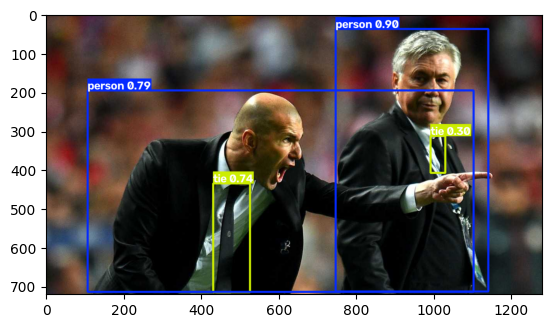

In [ ]:
plt.imshow(np.squeeze(result.render()))
plt.show()

# Real Time Video Capture Test


In [ ]:
import torch, cv2, numpy as np
from base64 import b64decode, b64encode
from IPython.display import display, Javascript, HTML, clear_output
from google.colab.output import eval_js

# Load model
model = torch.hub.load('ultralytics/yolov5', 'yolov5s', trust_repo=True)

# HTML & JS template that creates a persistent image tag and registers helper functions globally
html_layout = HTML('''
<div style="display: flex; flex-direction: column; align-items: center;">
  <img id="webcam_display" style="width: 640px; height: 480px; border: 2px solid #555; border-radius: 8px;" />
</div>
''')

js_helpers = Javascript('''
async function startCam() {
  if (window.cam) return;
  const video = document.createElement('video');
  video.style.display = 'none';
  document.body.appendChild(video);
  const stream = await navigator.mediaDevices.getUserMedia({video: true});
  video.srcObject = stream;
  await video.play();
  const canvas = document.createElement('canvas');
  canvas.width = 640; canvas.height = 480;
  window.cam = {video, stream, canvas};
}

function grab() {
  if (!window.cam) return null;
  const {video, canvas} = window.cam;
  canvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
  return canvas.toDataURL('image/jpeg', 0.8);
}

function updateDisplay(base64Image) {
  const img = document.getElementById("webcam_display");
  if (img) {
    img.src = base64Image;
  }
}

function stopCam() {
  if (window.cam && window.cam.stream) {
    window.cam.stream.getTracks().forEach(t => t.stop());
    window.cam = null;
  }
}

window.startCam = startCam;
window.grab = grab;
window.updateDisplay = updateDisplay;
window.stopCam = stopCam;
''')

# Render layout and load persistent JS functions
display(html_layout)
display(js_helpers)

# Start Camera
eval_js('startCam()')

try:
    while True:
        # Grab frame via JavaScript
        data = eval_js('grab()')
        if not data:
            continue

        # Decode base64 image data to OpenCV image
        frame = cv2.imdecode(np.frombuffer(b64decode(data.split(',')[1]), np.uint8), 1)

        # Run YOLO inference (convert BGR to RGB)
        results = model(frame[..., ::-1])
        annotated = np.squeeze(results.render())[..., ::-1]

        # Convert annotated frame back to jpeg base64
        _, buffer = cv2.imencode('.jpg', annotated)
        annotated_b64 = b64encode(buffer).decode('utf-8')
        annotated_data_url = f"data:image/jpeg;base64,{annotated_b64}"

        # Update the persistent image tag directly in JS without clearing output
        eval_js(f'updateDisplay("{annotated_data_url}")')

except KeyboardInterrupt:
    print("Stream stopped by user.")
finally:
    try:
        eval_js('stopCam()')
    except Exception:
        pass

YOLOv5 🚀 2026-10-29 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


<IPython.core.display.Javascript object>

Stream stopped by user.


# Trainning Data From Scratch

In [ ]:
import torch, cv2, os, time, uuid, glob, numpy as np
from base64 import b64decode
from IPython.display import display, Javascript, clear_output
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow


In [ ]:
print(torch.__version__, torch.cuda.is_available())

2.11.0+cu130 True


In [ ]:
display(Javascript('''
async function startCam() {
  const video = document.createElement('video');
  video.style.display = 'none';
  document.body.appendChild(video);
  const stream = await navigator.mediaDevices.getUserMedia({video: true});
  video.srcObject = stream;
  await video.play();
  const canvas = document.createElement('canvas');
  canvas.width = 640; canvas.height = 480;
  window.cam = {video, stream, canvas};
}
function grab() {
  const {video, canvas} = window.cam;
  canvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
  return canvas.toDataURL('image/jpeg', 0.9);
}
function stopCam() { window.cam.stream.getTracks().forEach(t => t.stop()); }
'''))

def get_frame():
    data = eval_js('grab()')
    return cv2.imdecode(np.frombuffer(b64decode(data.split(',')[1]), np.uint8), 1)

<IPython.core.display.Javascript object>

In [ ]:
import os, time, uuid, cv2, numpy as np
from base64 import b64decode
from IPython.display import display, Javascript
from google.colab.output import eval_js

# Define and display the Javascript functions globally on the window object
js_helpers = Javascript('''
async function startCam() {
  if (window.cam) return;
  const video = document.createElement('video');
  video.style.display = 'none';
  document.body.appendChild(video);
  const stream = await navigator.mediaDevices.getUserMedia({video: true});
  video.srcObject = stream;
  await video.play();
  const canvas = document.createElement('canvas');
  canvas.width = 640; canvas.height = 480;
  window.cam = {video, stream, canvas};
}

function grab() {
  if (!window.cam) return null;
  const {video, canvas} = window.cam;
  canvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
  return canvas.toDataURL('image/jpeg', 0.9);
}

function stopCam() {
  if (window.cam && window.cam.stream) {
    window.cam.stream.getTracks().forEach(t => t.stop());
    window.cam = null;
  }
}

window.startCam = startCam;
window.grab = grab;
window.stopCam = stopCam;
''')

display(js_helpers)

def get_frame():
    data = eval_js('grab()')
    if not data:
        raise RuntimeError("Camera grab failed. Make sure the webcam stream is active.")
    return cv2.imdecode(np.frombuffer(b64decode(data.split(',')[1]), np.uint8), 1)

IMAGES_PATH = '/content/data/raw'
labels = ['awake', 'drowsy']
number_imgs = 20          # aiming for 20 images per class
os.makedirs(IMAGES_PATH, exist_ok=True)

# Start Camera
eval_js('startCam()')
time.sleep(2) # Allow camera initialization

try:
    for label in labels:
        print(f'Get ready: "{label}" starts in 5s')
        time.sleep(5)
        for i in range(number_imgs):
            frame = get_frame()
            filename = os.path.join(IMAGES_PATH, f'{label}.{uuid.uuid1()}.jpg')
            cv2.imwrite(filename, frame)
            print(f'Captured {i+1}/{number_imgs} for {label}')
            time.sleep(0.5)
        print(f'Done {label}\n')
finally:
    try:
        eval_js('stopCam()')
    except Exception:
        pass

<IPython.core.display.Javascript object>

Get ready: "awake" starts in 5s
Captured 1/20 for awake
Captured 2/20 for awake
Captured 3/20 for awake
Captured 4/20 for awake
Captured 5/20 for awake
Captured 6/20 for awake
Captured 7/20 for awake
Captured 8/20 for awake
Captured 9/20 for awake
Captured 10/20 for awake
Captured 11/20 for awake
Captured 12/20 for awake
Captured 13/20 for awake
Captured 14/20 for awake
Captured 15/20 for awake
Captured 16/20 for awake
Captured 17/20 for awake
Captured 18/20 for awake
Captured 19/20 for awake
Captured 20/20 for awake
Done awake

Get ready: "drowsy" starts in 5s
Captured 1/20 for drowsy
Captured 2/20 for drowsy
Captured 3/20 for drowsy
Captured 4/20 for drowsy
Captured 5/20 for drowsy
Captured 6/20 for drowsy
Captured 7/20 for drowsy
Captured 8/20 for drowsy
Captured 9/20 for drowsy
Captured 10/20 for drowsy
Captured 11/20 for drowsy
Captured 12/20 for drowsy
Captured 13/20 for drowsy
Captured 14/20 for drowsy
Captured 15/20 for drowsy
Captured 16/20 for drowsy
Captured 17/20 for drowsy

In [ ]:
!zip -qr /content/raw_images.zip /content/data/raw
from google.colab import files
files.download('/content/raw_images.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [64]:
!pip install roboflow -q

In [66]:
from roboflow import Roboflow

rf = Roboflow(api_key="Your-API-Key")
project = rf.workspace("workspace name").project("projectname")
dataset = project.version(1).download("yolov5")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Object-Detection-1 in yolov5pytorch:: 100%|██████████| 84/84 [00:00<00:00, 7162.90it/s]


In [67]:
yaml_text = f"""path: {dataset.location}
train: train/images
val: valid/images
nc: 2
names: ['awake', 'drowsy']
"""
open('/content/dataset.yml', 'w').write(yaml_text)

112

In [68]:
!python train.py --img 320 --batch 8 --epochs 300 --data /content/dataset.yml --weights yolov5s.pt --workers 2 --cache --freeze 10 --patience 100

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1793280689.306716   43558 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=/content/dataset.yml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=300, batch_size=8, imgsz=320, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=2, project=runs/train,

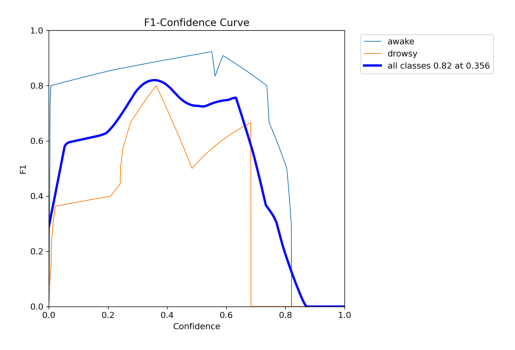

In [70]:
img_path = '/content/yolov5/runs/train/exp/F1_curve.png'
img_data = plt.imread(img_path)
plt.imshow(img_data)
plt.axis('off')
plt.show()

runs/train/exp/weights/best.pt


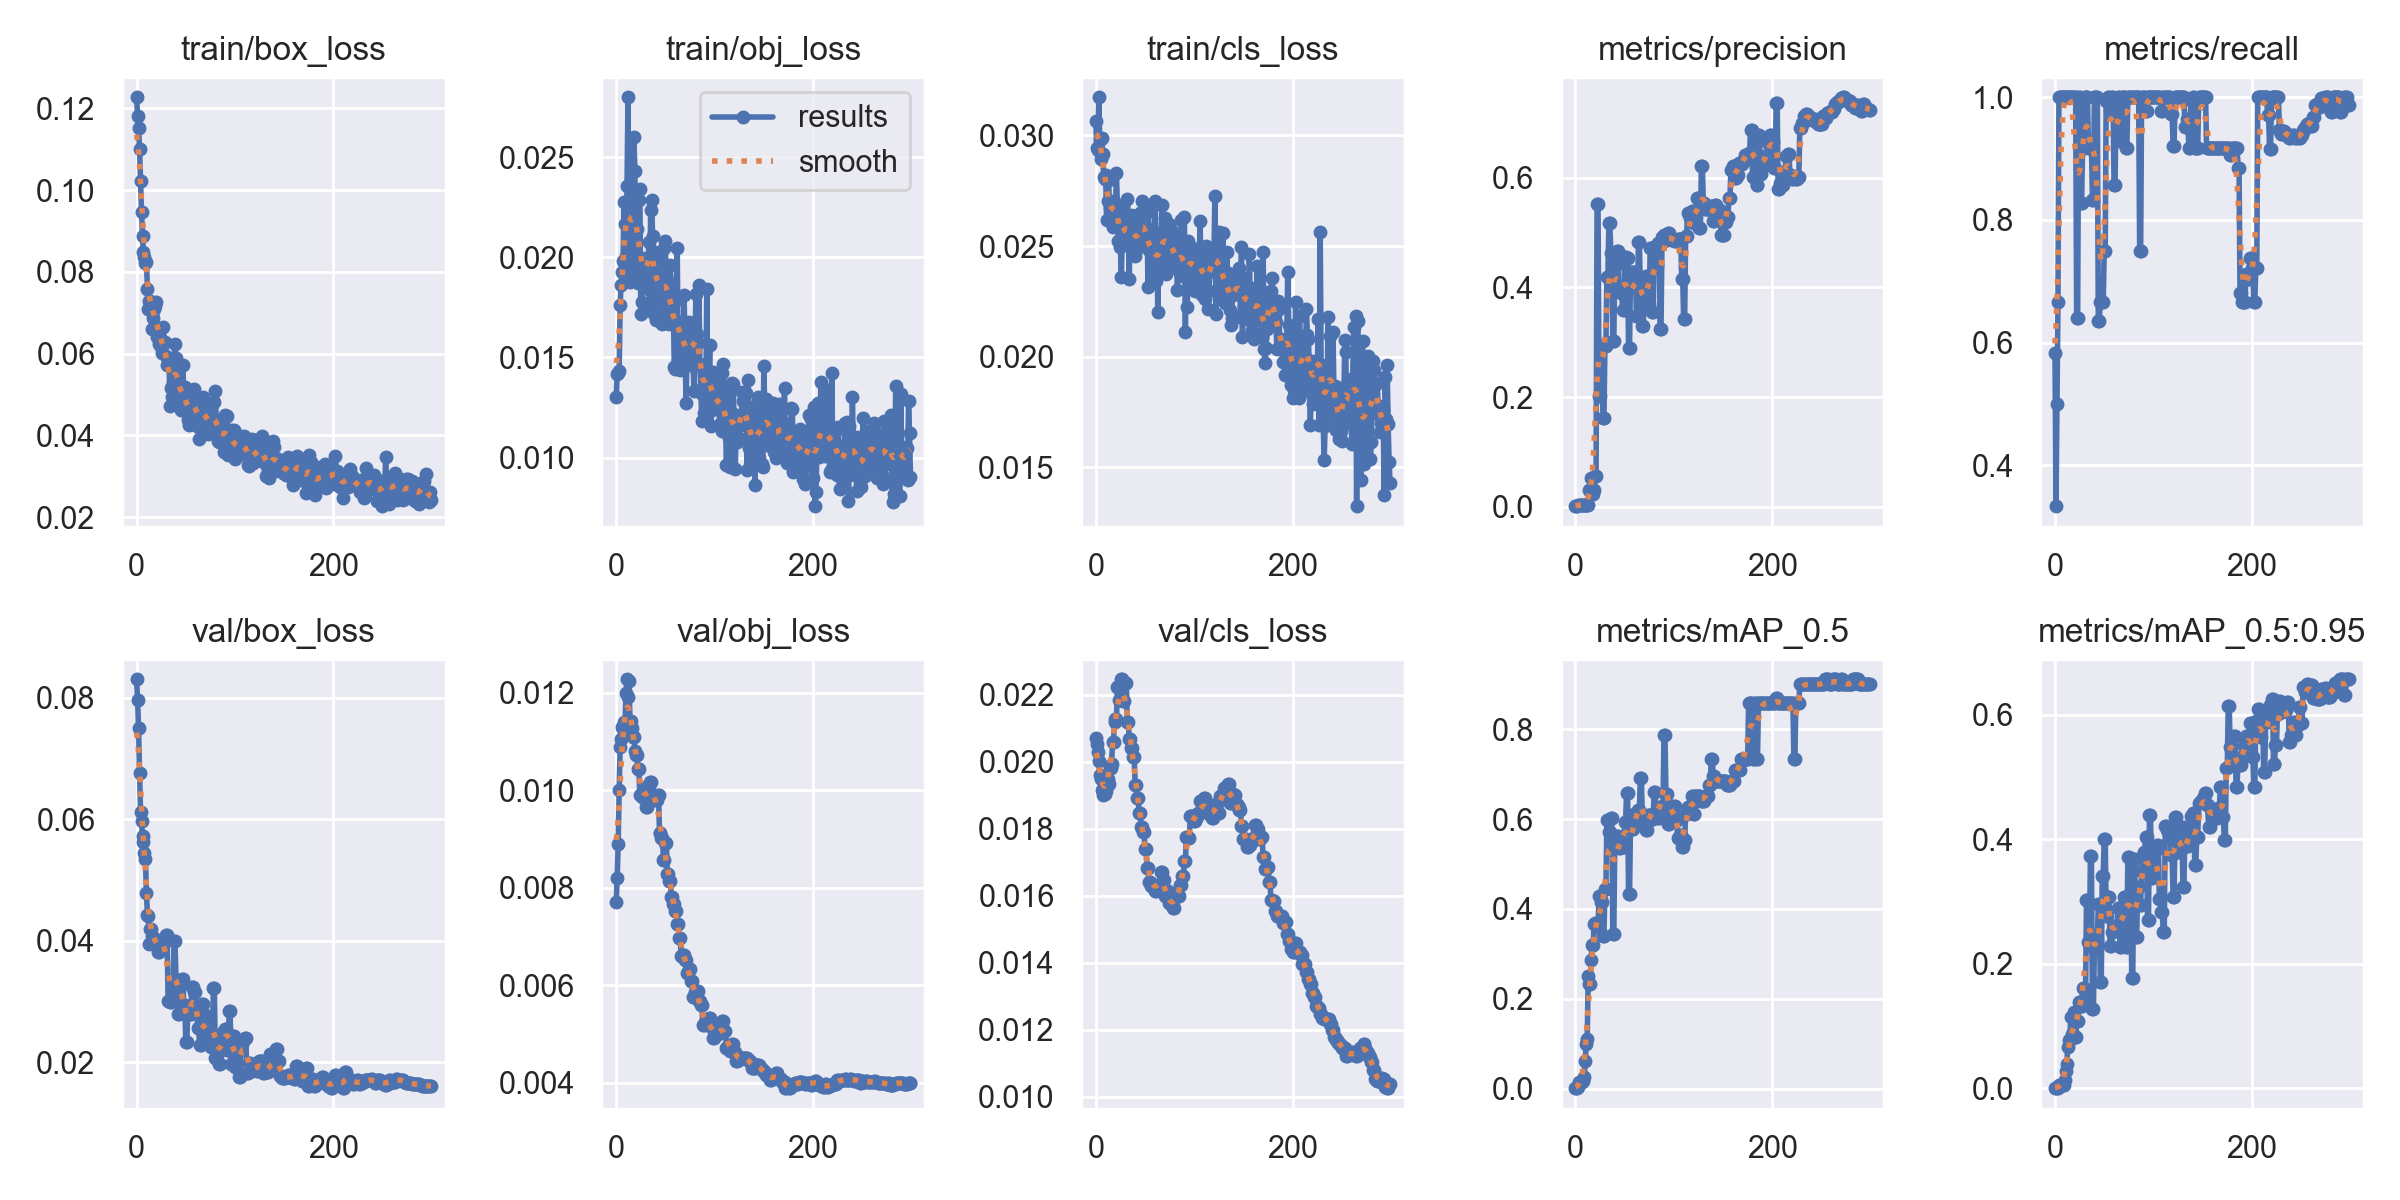

Mounted at /content/drive


In [71]:
from IPython.display import Image, display
from google.colab import drive

# find the most recent training run (if multiple runs then)
latest = sorted(glob.glob('runs/train/exp*'), key=os.path.getmtime)[-1]
weights = f'{latest}/weights/best.pt'
print(weights)

display(Image(f'{latest}/results.png'))   # loss and mAP curves

drive.mount('/content/drive')
!cp -r {latest}/weights /content/drive/MyDrive/drowsiness_weights

# Load Model

YOLOv5 🚀 2026-10-29 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
image 1/1: 512x512 1 drowsy
Speed: 5.0ms pre-process, 28.9ms inference, 1.7ms NMS per image at shape (1, 3, 640, 640)


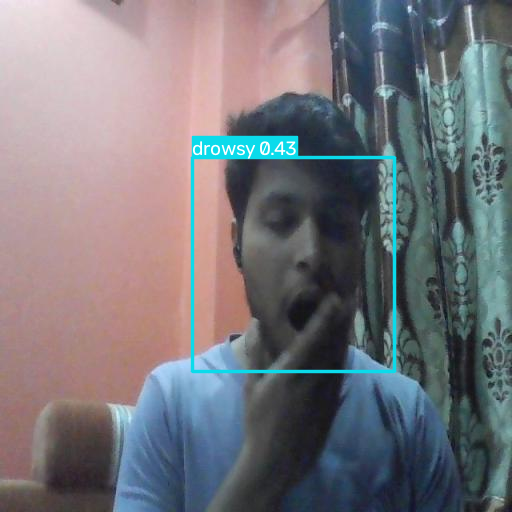

In [72]:
model = torch.hub.load('/content/yolov5', 'custom', path=weights, source='local')
model.conf = 0.4   # minimum confidence; lower it if nothing is detected

# test on a validation image
img = glob.glob(f'{dataset.location}/valid/images/*.jpg')[0]
results = model(img)
results.print()
cv2_imshow(np.squeeze(results.render())[..., ::-1])

# Live Detection

In [80]:
import torch, cv2, numpy as np
from base64 import b64decode, b64encode
from IPython.display import display, Javascript, HTML, clear_output
from google.colab.output import eval_js

# Ensure model is ready
if 'model' not in globals():
    latest = sorted(glob.glob('runs/train/exp*'), key=os.path.getmtime)[-1]
    weights = f'{latest}/weights/best.pt'
    model = torch.hub.load('/content/yolov5', 'custom', path=weights, source='local')
    model.conf = 0.4

# HTML layout containing a persistent display image to avoid constantly clearing cell output
html_layout = HTML('''
<div style="display: flex; flex-direction: column; align-items: center;">
  <img id="webcam_inference_display" style="width: 640px; height: 480px; border: 2px solid #555; border-radius: 8px;" />
</div>
''')

js_helpers = Javascript('''
async function startCam() {
  if (window.cam) return;
  const video = document.createElement('video');
  video.style.display = 'none';
  document.body.appendChild(video);
  const stream = await navigator.mediaDevices.getUserMedia({video: true});
  video.srcObject = stream;
  await video.play();
  const canvas = document.createElement('canvas');
  canvas.width = 640; canvas.height = 480;
  window.cam = {video, stream, canvas};
}

function grab() {
  if (!window.cam) return null;
  const {video, canvas} = window.cam;
  canvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
  return canvas.toDataURL('image/jpeg', 0.8);
}

function updateDisplay(base64Image) {
  const img = document.getElementById("webcam_inference_display");
  if (img) {
    img.src = base64Image;
  }
}

function stopCam() {
  if (window.cam && window.cam.stream) {
    window.cam.stream.getTracks().forEach(t => t.stop());
    window.cam = null;
  }
}

window.startCam = startCam;
window.grab = grab;
window.updateDisplay = updateDisplay;
window.stopCam = stopCam;
''')

display(html_layout)
display(js_helpers)

# Start Camera
eval_js('startCam()')
time.sleep(2.0) # Give camera hardware time to warm up

try:
    while True:
        data = eval_js('grab()')
        if not data:
            continue

        # Decode base64 frame data
        frame = cv2.imdecode(np.frombuffer(b64decode(data.split(',')[1]), np.uint8), 1)

        # Run drowsiness detection (Convert BGR to RGB)
        results = model(frame[..., ::-1])
        annotated = np.squeeze(results.render())[..., ::-1]

        # Encode annotated image back to base64 for JS display update
        _, buffer = cv2.imencode('.jpg', annotated)
        annotated_b64 = b64encode(buffer).decode('utf-8')
        annotated_data_url = f"data:image/jpeg;base64,{annotated_b64}"

        eval_js(f'updateDisplay("{annotated_data_url}")')

except KeyboardInterrupt:
    print("Stream stopped by user.")
finally:
    try:
        eval_js('stopCam()')
    except Exception:
        pass

<IPython.core.display.Javascript object>

Stream stopped by user.
